# Práctica 2. EDA y preparación de datasets

**Datasets:** Titanic (supervivencia, 891 filas) y Telco Customer Churn (abandono de clientes, 7,043 filas).

**Objetivo:** diagnosticar la calidad de los datos, justificar decisiones de preprocesamiento y medir su efecto sobre un clasificador (regresión logística con validación cruzada estratificada de 5 folds y evaluación final en un conjunto de prueba).

**Integrantes:** Dávila Martínez Brayan, Hernández Alonso Diego Raymundo, Martínez Rios Edson Jared y Pallares Hernández Oscar.

**Contenido:** 1. Carga y comprensión de los datos · 2. Data profiling · 3. Análisis exploratorio · 4. Imputación · 5. Outliers y winsorización · 6. Desbalance · 7. Evaluación final · 8. Conclusiones · 9. Declaración de uso de IA

## 1. Carga de datos
Se cargan ambos archivos desde la carpeta `Data/`. Se verifican las dimensiones esperadas y la distribución de la clase objetivo.

In [1]:
import pandas as pd
import os

base = "Data/" if os.path.exists("Data") else ""

titanic = pd.read_csv(base + "train.csv")
telco = pd.read_csv(base + "WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Titanic:", titanic.shape)
print("Telco:", telco.shape)
print(titanic["Survived"].value_counts())
print(telco["Churn"].value_counts())

Titanic: (891, 12)
Telco: (7043, 21)
Survived
0    549
1    342
Name: count, dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64


### 1.1 Comprensión de los datasets

| | **Titanic** | **Telco Customer Churn** |
|---|---|---|
| Fuente | Kaggle, competencia *Titanic - Machine Learning from Disaster* (`train.csv`): https://www.kaggle.com/competitions/titanic/data | Kaggle, dataset publicado por BlastChar a partir de los *IBM Sample Data Sets*: https://www.kaggle.com/datasets/blastchar/telco-customer-churn |
| Licencia / condiciones de uso | Kaggle indica "Subject to Competition Rules". Las reglas permiten usar los datos solo con fines no comerciales, académicos y de educación, y piden no redistribuirlos fuera de la competencia. | Kaggle indica "Data files © Original Authors": los derechos son de los autores originales (IBM) y no hay una licencia abierta declarada. Lo usamos solo con fines académicos. |
| Filas x columnas | 891 x 12 | 7,043 x 21 |
| Unidad de análisis | Un pasajero del Titanic | Un cliente de una compañía telefónica (una foto en un momento dado) |
| Variable objetivo | `Survived`: 0 = no sobrevivió, 1 = sobrevivió | `Churn`: "Yes" = el cliente se dio de baja en el último mes, "No" = sigue siendo cliente |
| ¿Disponible antes de predecir? | No. La supervivencia se conoce después del naufragio; el análisis es retrospectivo. | No. El abandono se conoce cuando ocurre; un modelo real tendría que predecirlo con datos previos a la baja. |
| Identificadores | `PassengerId` y `Name` (100 % únicos) y `Ticket` (681 valores distintos para 891 pasajeros). Se excluyen porque no generalizan. | `customerID` (100 % único). Se excluye. |
| Posible fuga o información indirecta | `Name` contiene el título (Mr, Mrs, Miss, Master), que codifica sexo y edad; `Cabin` y `Ticket` se relacionan con la clase. Se excluyen. | `TotalCharges` es casi `tenure x MonthlyCharges`. Además, `tenure` y los cargos se miden en el momento de la foto, que para quien se fue coincide con su baja. |
| Riesgos éticos | El sexo, la clase y la edad determinaron quién sobrevivió. Un modelo reproduce ese sesgo histórico y no debe usarse para decidir sobre personas. | `gender` y `SeniorCitizen` son atributos sensibles; usarlos para dar ofertas o atención distinta podría tratar de forma desigual a mujeres o adultos mayores. |

**Atributos principales**

| Dataset | Atributo | Tipo | Significado |
|---|---|---|---|
| Titanic | `Pclass` | entero (categórica ordinal) | Clase del boleto: 1 = primera, 2 = segunda, 3 = tercera |
| Titanic | `Sex` | texto (categórica) | male / female |
| Titanic | `Age` | decimal | Edad en años; es fraccional si es menor de 1 año y termina en .5 si fue estimada |
| Titanic | `SibSp`, `Parch` | enteros | Hermanos o cónyuge a bordo; padres o hijos a bordo |
| Titanic | `Fare` | decimal | Tarifa pagada |
| Titanic | `Embarked` | texto (categórica) | Puerto de embarque: C = Cherbourg, Q = Queenstown, S = Southampton |
| Telco | `tenure` | entero | Meses que lleva como cliente |
| Telco | `MonthlyCharges`, `TotalCharges` | decimal (`TotalCharges` llega como texto) | Cargo mensual y cargo acumulado |
| Telco | `Contract`, `InternetService`, `PaymentMethod` | texto (categóricas) | Tipo de contrato, servicio de internet y forma de pago |
| Telco | `gender`, `SeniorCitizen`, `Partner`, `Dependents` | texto / 0-1 (categóricas) | Datos demográficos del cliente |
| Telco | `PhoneService`, `MultipleLines`, `OnlineSecurity`, ... | texto (categóricas) | Servicios contratados (Yes / No / sin servicio) |

## 2. Data profiling
Se definen funciones reutilizables que reportan, por dataset:
- **Numéricas:** tipo, valores válidos, nulos y su porcentaje, únicos, mínimo, máximo, media, mediana, desviación estándar, percentiles y asimetría.
- **Categóricas:** tipo, nulos y su porcentaje, únicos, moda y la tabla completa de frecuencias (absoluta y relativa) de cada categoría, donde los ausentes aparecen como `(ausente)`.
- **Revisiones generales:** filas duplicadas, columnas constantes o casi constantes, identificadores únicos, etiquetas inconsistentes y valores fuera del dominio esperado.

In [2]:
import numpy as np

def perfil_general(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%nulos": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
        "%unicos": (df.nunique() / len(df) * 100).round(2),
    })

def perfil_numerico(df):
    num = df.select_dtypes(include="number")
    d = num.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
    d = d.rename(columns={"count": "validos", "mean": "media", "50%": "mediana", "std": "desv_est"})
    d["tipo"] = num.dtypes.astype(str)
    d["nulos"] = num.isna().sum()
    d["%nulos"] = num.isna().mean() * 100
    d["unicos"] = num.nunique()
    d["asimetria"] = num.skew()
    orden = ["tipo", "validos", "nulos", "%nulos", "unicos", "min", "max", "media", "mediana",
             "desv_est", "1%", "5%", "25%", "75%", "95%", "99%", "asimetria"]
    return d[orden].round(2)

def perfil_categorico(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%nulos": (df.isna().mean() * 100).round(2),
        "unicos": df.nunique(),
        "moda": df.mode().iloc[0],
        "%moda": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in df],
    })

def frecuencias(df, columnas):
    # Tabla larga con la frecuencia absoluta y relativa de TODAS las categorías.
    # dropna=False hace que los ausentes también aparezcan como una fila más.
    tablas = []
    for c in columnas:
        n = df[c].value_counts(dropna=False)
        tablas.append(pd.DataFrame({
            "variable": c,
            "categoria": ["(ausente)" if pd.isna(v) else str(v) for v in n.index],
            "n": n.values,
            "%": (n.values / len(df) * 100).round(2),
        }))
    return pd.concat(tablas).set_index(["variable", "categoria"])

def revisar_categorias(df, dominio):
    # Busca etiquetas que solo cambian por mayúsculas o espacios ("Yes" vs " yes")
    # y valores que no pertenecen al dominio esperado de cada variable.
    for c, esperados in dominio.items():
        valores = df[c].dropna().astype(str)
        inconsistentes = valores.str.strip().str.lower().nunique() < valores.nunique()
        fuera = sorted(set(valores.unique()) - set(esperados))
        print(f"{c:18s} etiquetas inconsistentes: {'sí' if inconsistentes else 'no'} | fuera de dominio: {fuera if fuera else 'ninguno'}")

def chequeos(df):
    print("Filas duplicadas:", df.duplicated().sum())
    print("Columnas constantes:", [c for c in df if df[c].nunique(dropna=False) <= 1])
    print("Casi constantes (>95% un valor):",
          [c for c in df if df[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.95])
    print("Identificadores (100% únicos):", [c for c in df if df[c].nunique() == len(df)])

### 2.1 Profiling de Titanic
`Pclass` y `Survived` vienen como enteros, pero son categóricas: se perfilan con las frecuencias. Las numéricas reales son `Age`, `SibSp`, `Parch` y `Fare`.

In [3]:
display(perfil_general(titanic))
display(perfil_numerico(titanic[["Age", "SibSp", "Parch", "Fare"]]))
display(perfil_categorico(titanic[["Survived", "Pclass", "Sex", "Embarked", "Name", "Ticket", "Cabin"]]))
chequeos(titanic)

,tipo,nulos,%nulos,unicos,%unicos
PassengerId,int64,0,0.00,891,100.00
Survived,int64,0,0.00,2,0.22
Pclass,int64,0,0.00,3,0.34
Name,str,0,0.00,891,100.00
Sex,str,0,0.00,2,0.22
Age,float64,177,19.87,88,9.88
SibSp,int64,0,0.00,7,0.79
Parch,int64,0,0.00,7,0.79
Ticket,str,0,0.00,681,76.43
Fare,float64,0,0.00,248,27.83


,tipo,validos,nulos,%nulos,unicos,min,max,media,mediana,desv_est,1%,5%,25%,75%,95%,99%,asimetria
Age,float64,714.0,177,19.87,88,0.42,80.00,29.70,28.00,14.53,1.0,4.00,20.12,38.0,56.00,65.87,0.39
SibSp,int64,891.0,0,0.00,7,0.00,8.00,0.52,0.00,1.10,0.0,0.00,0.00,1.0,3.00,5.00,3.70
Parch,int64,891.0,0,0.00,7,0.00,6.00,0.38,0.00,0.81,0.0,0.00,0.00,0.0,2.00,4.00,2.75
Fare,float64,891.0,0,0.00,248,0.00,512.33,32.20,14.45,49.69,0.0,7.22,7.91,31.0,112.08,249.01,4.79


,tipo,nulos,%nulos,unicos,moda,%moda
Survived,int64,0,0.00,2,0.0,61.6
Pclass,int64,0,0.00,3,3.0,55.1
Sex,str,0,0.00,2,male,64.8
Embarked,str,2,0.22,3,S,72.4
Name,str,0,0.00,891,"Abbing, Mr. Anthony",0.1
Ticket,str,0,0.00,681,1601,0.8
Cabin,str,687,77.10,147,B96 B98,2.0


Filas duplicadas: 0
Columnas constantes: []
Casi constantes (>95% un valor): []
Identificadores (100% únicos): ['PassengerId', 'Name']


Tabla de frecuencias de las categóricas con pocas categorías. `Name`, `Ticket` y `Cabin` no se tabulan porque casi todos sus valores son distintos (son identificadores o texto libre).

In [4]:
display(frecuencias(titanic, ["Survived", "Pclass", "Sex", "Embarked"]))

dominio_titanic = {"Survived": ["0", "1"], "Pclass": ["1", "2", "3"],
                   "Sex": ["male", "female"], "Embarked": ["C", "Q", "S"]}
revisar_categorias(titanic, dominio_titanic)

# Valores numéricos potencialmente inválidos según el significado de cada atributo
invalidos_titanic = pd.Series({
    "Age fuera de [0, 100]": ((titanic["Age"] < 0) | (titanic["Age"] > 100)).sum(),
    "Age menor a 1 (bebés, válido)": (titanic["Age"] < 1).sum(),
    "Age estimada (xx.5, válido)": ((titanic["Age"] % 1 == 0.5) & (titanic["Age"] > 1)).sum(),
    "SibSp o Parch negativos": ((titanic["SibSp"] < 0) | (titanic["Parch"] < 0)).sum(),
    "Fare negativa": (titanic["Fare"] < 0).sum(),
    "Fare = 0 (sospechoso)": (titanic["Fare"] == 0).sum(),
}, name="filas")
display(invalidos_titanic.to_frame())

n      %
variable categoria            
Survived 0          549  61.62
         1          342  38.38
Pclass   3          491  55.11
         1          216  24.24
         2          184  20.65
Sex      male       577  64.76
         female     314  35.24
Embarked S          644  72.28
         C          168  18.86
         Q           77   8.64
         (ausente)    2   0.22

Survived           etiquetas inconsistentes: no | fuera de dominio: ninguno
Pclass             etiquetas inconsistentes: no | fuera de dominio: ninguno
Sex                etiquetas inconsistentes: no | fuera de dominio: ninguno
Embarked           etiquetas inconsistentes: no | fuera de dominio: ninguno


,filas
"Age fuera de [0, 100]",0
"Age menor a 1 (bebés, válido)",7
"Age estimada (xx.5, válido)",18
SibSp o Parch negativos,0
Fare negativa,0
Fare = 0 (sospechoso),15


### Hallazgos del profiling de Titanic
- **Ausentes:** `Age` tiene 177 nulos (19.87 %), `Cabin` 687 (77.10 %) y `Embarked` solo 2 (0.22 %). En la tabla de frecuencias los 2 de `Embarked` aparecen como `(ausente)`.
- **Distribuciones:** `Fare` tiene asimetría de 4.79 (mediana 14.45, máximo 512.33); `SibSp` (3.70) y `Parch` (2.75) también están sesgadas porque la mayoría viajaba sin familiares.
- **Dominio:** no hay edades negativas ni mayores a 100; los 7 menores de 1 año y las 18 edades terminadas en .5 son válidas según el diccionario de Kaggle. Hay 15 pasajeros con `Fare = 0` repartidos en las tres clases: es un valor sospechoso (quizá boletos de cortesía o de tripulación) que se documenta sin modificar.
- **Categorías:** `Sex`, `Embarked` y `Pclass` no tienen etiquetas inconsistentes ni valores fuera de dominio. La moda de `Embarked` es "S" (72.4 %).
- **Estructura:** `PassengerId` y `Name` son identificadores únicos; `Ticket` tiene 681 valores para 891 pasajeros (boletos compartidos por familias). No hay filas duplicadas ni columnas constantes o casi constantes.

### 2.2 Profiling de Telco (datos tal como vienen)

In [5]:
display(perfil_general(telco))
chequeos(telco)

,tipo,nulos,%nulos,unicos,%unicos
customerID,str,0,0.0,7043,100.00
gender,str,0,0.0,2,0.03
SeniorCitizen,int64,0,0.0,2,0.03
Partner,str,0,0.0,2,0.03
Dependents,str,0,0.0,2,0.03
tenure,int64,0,0.0,73,1.04
PhoneService,str,0,0.0,2,0.03
MultipleLines,str,0,0.0,3,0.04
InternetService,str,0,0.0,3,0.04
OnlineSecurity,str,0,0.0,3,0.04


Filas duplicadas: 0
Columnas constantes: []
Casi constantes (>95% un valor): []
Identificadores (100% únicos): ['customerID']


### Hallazgos del profiling inicial de Telco
- `TotalCharges` viene como texto, por lo que en esta primera tabla aparece con 0 nulos aunque tiene valores vacíos (ausentes "ocultos"). Se corrige en el siguiente paso.
- `customerID` es un identificador único y no se usa en el modelo.
- `SeniorCitizen` es numérica (0/1) pero en realidad es categórica.
- No hay duplicados ni columnas constantes o casi constantes (la más cargada es `PhoneService`, con 90.3 % de "Yes").

### Corrección de `TotalCharges`
Procedimiento:
1. Identificar los valores que no se pueden leer como número (vacíos, espacios u otro texto).
2. Revisar qué representan esas filas.
3. Convertir la columna a numérica con `errors="coerce"` (lo inválido pasa a `NaN`). Antes se guarda una copia del dataset tal como venía (`telco_original`) y el CSV no se modifica.
4. Volver a perfilar: contar los nulos después de la conversión y recalcular porcentajes y estadísticos.

In [6]:
# 1. Valores que no se pueden interpretar como número
convertido = pd.to_numeric(telco["TotalCharges"], errors="coerce")
no_numericos = convertido.isna()
print("Valores no numéricos en TotalCharges:", no_numericos.sum())
print("Contenido de esos valores:", list(telco.loc[no_numericos, "TotalCharges"].unique()))

# 2. ¿Qué representan?
print(telco.loc[no_numericos, ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

# 3. Conversión (se conserva una copia del original)
telco_original = telco.copy()
telco["TotalCharges"] = convertido

Valores no numéricos en TotalCharges: 11
Contenido de esos valores: [' ']
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
3331  7644-OMVMY       0           19.85             
3826  3213-VVOLG       0           25.35             
4380  2520-SGTTA       0           20.00             
5218  2923-ARZLG       0           19.70             
6670  4075-WKNIU       0           73.35             
6754  2775-SEFEE       0           61.90             


Las 11 filas son cadenas con un espacio en blanco y **todas** corresponden a clientes con `tenure = 0`: son clientes nuevos a los que todavía no se les ha facturado. La ausencia es **estructural, no aleatoria**. Lógicamente su cargo acumulado sería 0; aun así se dejan como `NaN` en los datos y se imputan con la mediana **dentro del pipeline**, para que el valor se calcule solo con entrenamiento. Al ser 11 filas (0.16 %), la elección prácticamente no cambia los resultados.

Ahora se repite el profiling con la columna ya convertida.

In [7]:
# 4. Profiling actualizado después de la conversión
display(perfil_general(telco).loc[["tenure", "MonthlyCharges", "TotalCharges"]])
display(perfil_numerico(telco[["tenure", "MonthlyCharges", "TotalCharges"]]))

cat_telco = [c for c in telco.columns if c not in ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]
display(perfil_categorico(telco[cat_telco]))

,tipo,nulos,%nulos,unicos,%unicos
tenure,int64,0,0.00,73,1.04
MonthlyCharges,float64,0,0.00,1585,22.50
TotalCharges,float64,11,0.16,6530,92.72


,tipo,validos,nulos,%nulos,unicos,min,max,media,mediana,desv_est,1%,5%,25%,75%,95%,99%,asimetria
tenure,int64,7043.0,0,0.00,73,0.00,72.00,32.37,29.00,24.56,1.0,1.00,9.00,55.00,72.00,72.00,0.24
MonthlyCharges,float64,7043.0,0,0.00,1585,18.25,118.75,64.76,70.35,30.09,19.2,19.65,35.50,89.85,107.40,114.73,-0.22
TotalCharges,float64,7032.0,11,0.16,6530,18.80,8684.80,2283.30,1397.48,2266.77,19.9,49.60,401.45,3794.74,6923.59,8039.88,0.96


,tipo,nulos,%nulos,unicos,moda,%moda
gender,str,0,0.0,2,Male,50.5
SeniorCitizen,int64,0,0.0,2,0,83.8
Partner,str,0,0.0,2,No,51.7
Dependents,str,0,0.0,2,No,70.0
PhoneService,str,0,0.0,2,Yes,90.3
MultipleLines,str,0,0.0,3,No,48.1
InternetService,str,0,0.0,3,Fiber optic,44.0
OnlineSecurity,str,0,0.0,3,No,49.7
OnlineBackup,str,0,0.0,3,No,43.8
DeviceProtection,str,0,0.0,3,No,43.9


In [8]:
display(frecuencias(telco, cat_telco))

si_no = ["Yes", "No"]
dominio_telco = {"gender": ["Male", "Female"], "SeniorCitizen": ["0", "1"], "Partner": si_no,
                 "Dependents": si_no, "PhoneService": si_no, "PaperlessBilling": si_no, "Churn": si_no,
                 "MultipleLines": si_no + ["No phone service"],
                 "InternetService": ["DSL", "Fiber optic", "No"],
                 "Contract": ["Month-to-month", "One year", "Two year"],
                 "PaymentMethod": ["Electronic check", "Mailed check",
                                   "Bank transfer (automatic)", "Credit card (automatic)"]}
for c in ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]:
    dominio_telco[c] = si_no + ["No internet service"]
revisar_categorias(telco, dominio_telco)

# Valores numéricos potencialmente inválidos
con_meses = telco["tenure"] > 0
invalidos_telco = pd.Series({
    "tenure fuera de [0, 72]": ((telco["tenure"] < 0) | (telco["tenure"] > 72)).sum(),
    "tenure = 0 (cliente nuevo)": (telco["tenure"] == 0).sum(),
    "MonthlyCharges <= 0": (telco["MonthlyCharges"] <= 0).sum(),
    "TotalCharges nulo tras la conversión": telco["TotalCharges"].isna().sum(),
    "TotalCharges < MonthlyCharges (con tenure > 0)": (con_meses & (telco["TotalCharges"] < telco["MonthlyCharges"])).sum(),
}, name="filas")
display(invalidos_telco.to_frame())

n      %
variable         categoria                             
gender           Male                       3555  50.48
                 Female                     3488  49.52
SeniorCitizen    0                          5901  83.79
                 1                          1142  16.21
Partner          No                         3641  51.70
                 Yes                        3402  48.30
Dependents       No                         4933  70.04
                 Yes                        2110  29.96
PhoneService     Yes                        6361  90.32
                 No                          682   9.68
MultipleLines    No                         3390  48.13
                 Yes                        2971  42.18
                 No phone service            682   9.68
InternetService  Fiber optic                3096  43.96
                 DSL                        2421  34.37
                 No                         1526  21.67
OnlineSecurity   No                         3498  49.67
                 Yes                        2019  28.67
                 No internet service        1526  21.67
OnlineBackup     No                         3088  43.84
                 Yes                        2429  34.49
                 No internet service        1526  21.67
DeviceProtection No                         3095  43.94
                 Yes                        2422  34.39
                 No internet service        1526  21.67
TechSupport      No                         3473  49.31
                 Yes                        2044  29.02
                 No internet service        1526  21.67
StreamingTV      No                         2810  39.90
                 Yes                        2707  38.44
                 No internet service        1526  21.67
StreamingMovies  No                         2785  39.54
                 Yes                        2732  38.79
                 No internet service        1526  21.67
Contract         Month-to-month             3875  55.02
                 Two year                   1695  24.07
                 One year                   1473  20.91
PaperlessBilling Yes                        4171  59.22
                 No                         2872  40.78
PaymentMethod    Electronic check           2365  33.58
                 Mailed check               1612  22.89
                 Bank transfer (automatic)  1544  21.92
                 Credit card (automatic)    1522  21.61
Churn            No                         5174  73.46
                 Yes                        1869  26.54

gender             etiquetas inconsistentes: no | fuera de dominio: ninguno
SeniorCitizen      etiquetas inconsistentes: no | fuera de dominio: ninguno
Partner            etiquetas inconsistentes: no | fuera de dominio: ninguno
Dependents         etiquetas inconsistentes: no | fuera de dominio: ninguno
PhoneService       etiquetas inconsistentes: no | fuera de dominio: ninguno
PaperlessBilling   etiquetas inconsistentes: no | fuera de dominio: ninguno
Churn              etiquetas inconsistentes: no | fuera de dominio: ninguno
MultipleLines      etiquetas inconsistentes: no | fuera de dominio: ninguno
InternetService    etiquetas inconsistentes: no | fuera de dominio: ninguno
Contract           etiquetas inconsistentes: no | fuera de dominio: ninguno
PaymentMethod      etiquetas inconsistentes: no | fuera de dominio: ninguno
OnlineSecurity     etiquetas inconsistentes: no | fuera de dominio: ninguno
OnlineBackup       etiquetas inconsistentes: no | fuera de dominio: ninguno
DeviceProtec

,filas
"tenure fuera de [0, 72]",0
tenure = 0 (cliente nuevo),11
MonthlyCharges <= 0,0
TotalCharges nulo tras la conversión,11
TotalCharges < MonthlyCharges (con tenure > 0),0


### Hallazgos del profiling de Telco después de la conversión
- `TotalCharges` pasa a `float64` con **11 nulos (0.16 %)**; su media es 2,283.30, la mediana 1,397.48 y la asimetría 0.96 (cola a la derecha). Esos 11 son los clientes con `tenure = 0`.
- `tenure` va de 0 a 72 meses y `MonthlyCharges` de 18.25 a 118.75; no hay valores negativos ni fuera de rango, y ningún cliente tiene un cargo acumulado menor a su cargo mensual.
- Las categóricas no tienen etiquetas inconsistentes ni valores fuera de dominio. Lo que sí hay son categorías **redundantes**: "No internet service" (1,526 clientes en seis columnas) y "No phone service" (682) repiten lo que ya dicen `InternetService` y `PhoneService`.
- La clase `Churn` tiene 73.5 % de "No", lo que anticipa el desbalance de la sección 6.

### Correlaciones, redundancias y posibles fugas
Se revisan las correlaciones entre numéricas, la relación de cada numérica con el objetivo y si `TotalCharges` se puede reconstruir a partir de otras columnas.

In [9]:
# Correlaciones elevadas (incluyendo la correlación con el objetivo)
telco["Churn_bin"] = (telco["Churn"] == "Yes").astype(int)
print(telco[["tenure", "MonthlyCharges", "TotalCharges", "Churn_bin"]].corr().round(2), "\n")
print(titanic[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr().round(2), "\n")

# ¿TotalCharges es casi tenure x MonthlyCharges?
estimado = telco["tenure"] * telco["MonthlyCharges"]
error_rel = ((telco["TotalCharges"] - estimado).abs() / telco["TotalCharges"]).median()
print(f"Diferencia relativa mediana entre TotalCharges y tenure x MonthlyCharges: {error_rel:.1%}\n")

# Categorías potencialmente redundantes en Telco
for c in ["MultipleLines", "OnlineSecurity", "InternetService"]:
    print(telco[c].value_counts(), "\n")

                tenure  MonthlyCharges  TotalCharges  Churn_bin
tenure            1.00            0.25          0.83      -0.35
MonthlyCharges    0.25            1.00          0.65       0.19
TotalCharges      0.83            0.65          1.00      -0.20
Churn_bin        -0.35            0.19         -0.20       1.00 

          Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
Age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp        -0.04    0.08 -0.31   1.00   0.41  0.16
Parch         0.08    0.02 -0.19   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00 

Diferencia relativa mediana entre TotalCharges y tenure x MonthlyCharges: 2.0%

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64 

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: cou

**Interpretación.**
- En Telco, `tenure` y `TotalCharges` tienen correlación 0.83 y `TotalCharges` se aproxima a `tenure x MonthlyCharges` con una diferencia mediana de ~2 %: es casi una variable derivada. En Titanic, `Pclass` y `Fare` tienen correlación -0.55 (los boletos de primera son más caros).
- **Cuándo es un problema:** en una regresión logística, dos variables muy correlacionadas (multicolinealidad) hacen que los coeficientes sean inestables y difíciles de interpretar, aunque casi no afectan la capacidad de predecir. Por eso **no se elimina ninguna variable**: con 0.83 y -0.55 no hay redundancia perfecta y el objetivo de la práctica es medir el efecto del preprocesamiento, no interpretar coeficientes. Es un hallazgo exploratorio que se documenta.
- **Fuga de información:** ninguna variable tiene una correlación sospechosamente alta con el objetivo (la mayor en valor absoluto es `tenure` con -0.35 en Telco y `Pclass` con -0.34 en Titanic). Las fugas posibles son de otro tipo: el título dentro de `Name` (se excluye) y, en Telco, que `tenure` y `TotalCharges` se registran al momento de la baja, algo que hay que considerar si el modelo se usara en producción.

## 3. Análisis exploratorio
Para cada dataset se analizan dos distribuciones numéricas (histogramas), dos boxplots, gráficas categóricas, una matriz de correlación, la distribución de clases y la relación de los atributos con el objetivo. Debajo de cada figura se interpreta lo que muestra.

### EDA de Titanic
Cada gráfica responde una pregunta concreta:
- **Histogramas de `Age` y `Fare`:** ¿cómo se distribuyen y hay valores extremos?
- **Distribución de la clase:** ¿está desbalanceado el objetivo?
- **Boxplots de `Age` y `Fare` por `Survived`:** ¿separan las clases estas variables?
- **Matriz de correlación:** ¿qué variables numéricas se relacionan con sobrevivir y entre sí?
- **`Sex`, `Pclass` y `Embarked` vs. `Survived`:** ¿qué grupos sobreviven más?

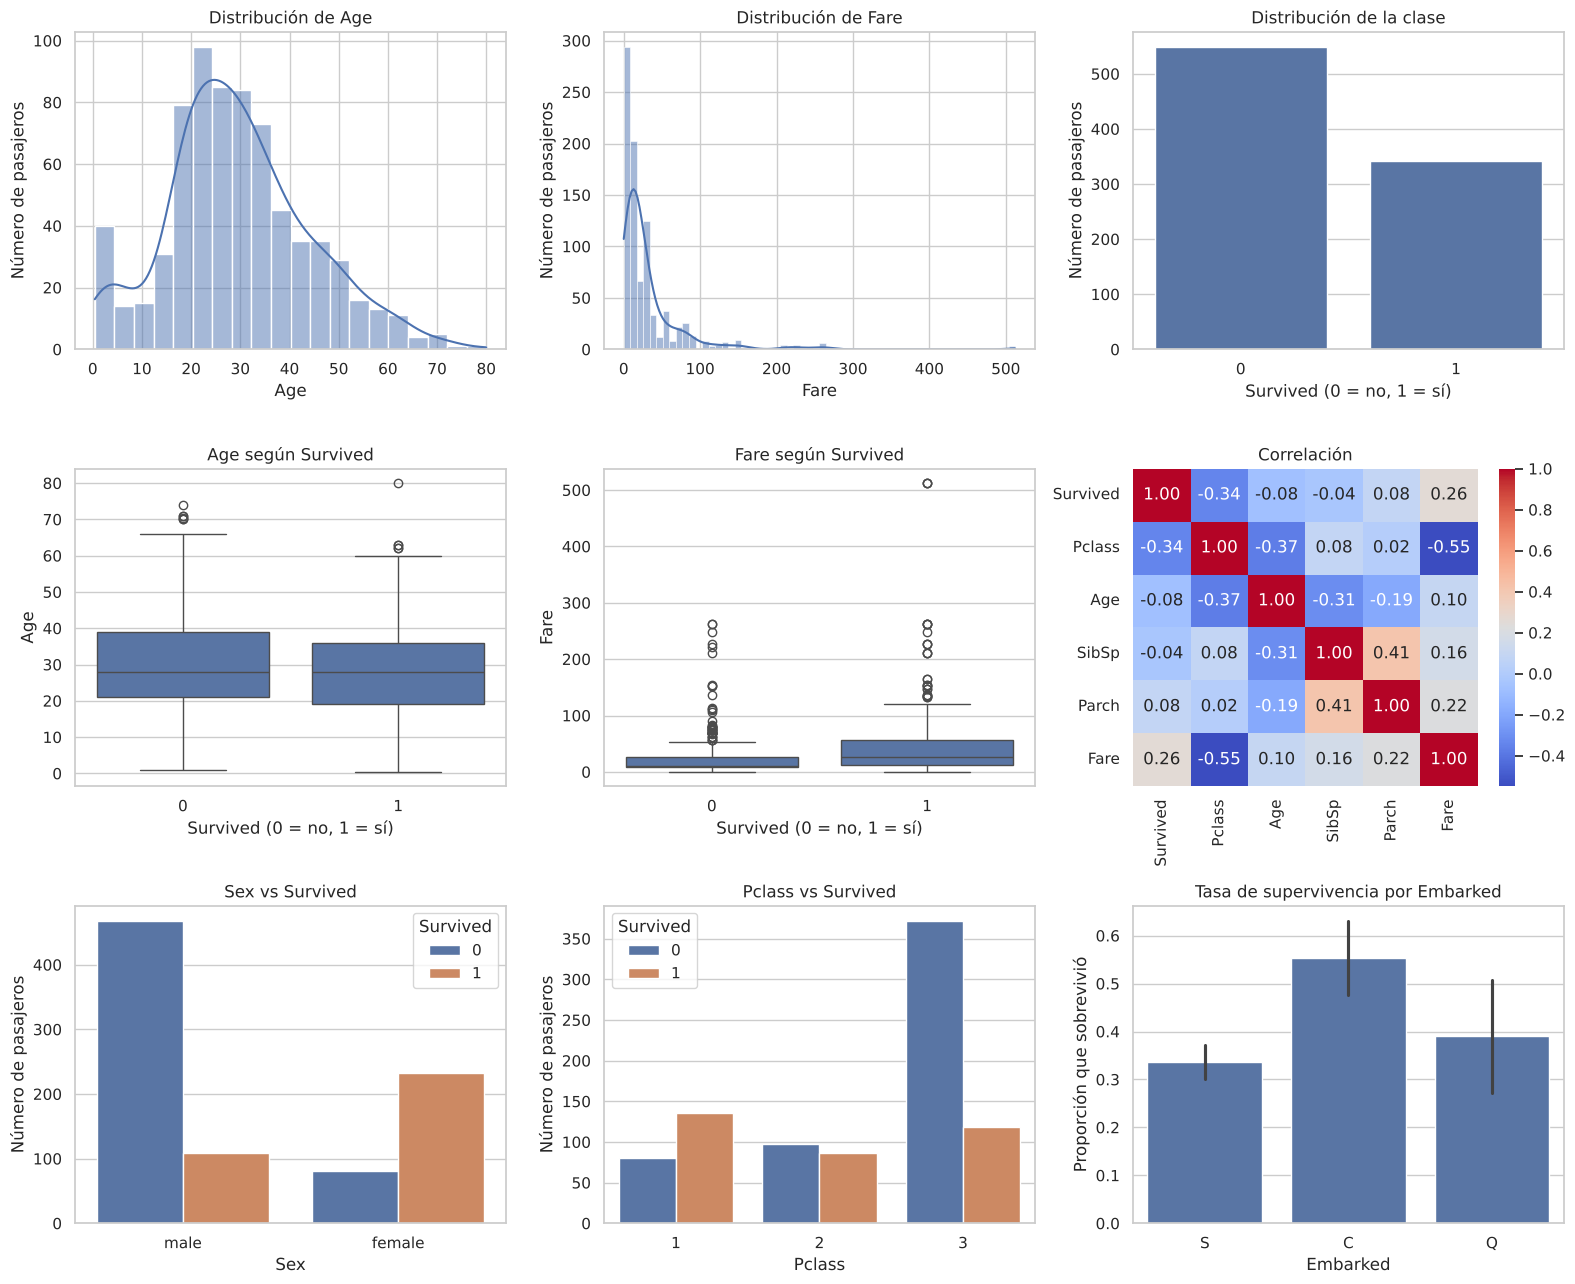

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64 

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64 

           Age  Fare
Survived            
0         28.0  10.5
1         28.0  26.0 

Proporción de cada clase por puerto:
 Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

etiqueta_surv = "Survived (0 = no, 1 = sí)"
fig, ax = plt.subplots(3, 3, figsize=(16, 13))

sns.histplot(titanic["Age"].dropna(), kde=True, ax=ax[0,0]); ax[0,0].set_title("Distribución de Age")
sns.histplot(titanic["Fare"], kde=True, ax=ax[0,1]); ax[0,1].set_title("Distribución de Fare")
sns.countplot(x="Survived", data=titanic, ax=ax[0,2]); ax[0,2].set_title("Distribución de la clase")

sns.boxplot(x="Survived", y="Age", data=titanic, ax=ax[1,0]); ax[1,0].set_title("Age según Survived")
sns.boxplot(x="Survived", y="Fare", data=titanic, ax=ax[1,1]); ax[1,1].set_title("Fare según Survived")
sns.heatmap(titanic[["Survived","Pclass","Age","SibSp","Parch","Fare"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1,2]); ax[1,2].set_title("Correlación")

sns.countplot(x="Sex", hue="Survived", data=titanic, ax=ax[2,0]); ax[2,0].set_title("Sex vs Survived")
sns.countplot(x="Pclass", hue="Survived", data=titanic, ax=ax[2,1]); ax[2,1].set_title("Pclass vs Survived")
sns.barplot(x="Embarked", y="Survived", data=titanic, ax=ax[2,2]); ax[2,2].set_title("Tasa de supervivencia por Embarked")

for a in [ax[0,2], ax[1,0], ax[1,1]]:
    a.set_xlabel(etiqueta_surv)
for a in [ax[0,0], ax[0,1], ax[0,2], ax[2,0], ax[2,1]]:
    a.set_ylabel("Número de pasajeros")
ax[2,2].set_ylabel("Proporción que sobrevivió")

plt.tight_layout(); plt.show()

# Cifras que respaldan la interpretación
print((titanic.groupby("Sex")["Survived"].mean() * 100).round(1), "\n")
print((titanic.groupby("Pclass")["Survived"].mean() * 100).round(1), "\n")
print(titanic.groupby("Survived")[["Age", "Fare"]].median(), "\n")
print("Proporción de cada clase por puerto:\n", pd.crosstab(titanic["Embarked"], titanic["Pclass"], normalize="index").round(2))

### Interpretación del EDA de Titanic
- **Distribución de `Age`:** casi simétrica (asimetría 0.39), concentrada entre 20 y 40 años y con niños pequeños. Como le falta el 19.9 % de los datos, la forma de imputar puede deformar esta distribución (sección 4).
- **Distribución de `Fare`:** cola muy larga a la derecha; la mayoría pagó menos de 50 y unos pocos más de 200 (hasta 512.33). Estos extremos son candidatos a winsorización (sección 5).
- **Distribución de la clase:** 549 no sobrevivieron y 342 sí (61.6 % vs. 38.4 %). La diferencia no es enorme, pero el IR = 1.61 supera el umbral de 1.5 (sección 6).
- **Boxplot de `Age` por `Survived`:** la mediana es 28 años en ambos grupos; la edad por sí sola casi no separa las clases (solo se nota que entre los sobrevivientes hay más niños).
- **Boxplot de `Fare` por `Survived`:** quienes sobrevivieron pagaron más (mediana 26.0 vs. 10.5) y casi todos los valores extremos están en ese grupo, lo que indica que las tarifas altas son legítimas y no errores.
- **Matriz de correlación:** `Pclass` (-0.34) y `Fare` (0.26) son las numéricas más relacionadas con sobrevivir, y entre ellas tienen -0.55. No incluye `Sex` por ser categórica, aunque es la variable más influyente.
- **`Sex` vs. `Survived`:** sobrevivió el 74.2 % de las mujeres y solo el 18.9 % de los hombres.
- **`Pclass` vs. `Survived`:** 63.0 % en primera, 47.3 % en segunda y 24.2 % en tercera.
- **`Embarked`:** Cherbourg tiene mayor tasa (55 %), pero es porque el 51 % de sus pasajeros iba en primera clase. Es una relación confundida con la clase, no un efecto del puerto.

**Implicaciones para el preprocesamiento:** `Pclass` se trata como categórica, `Fare` necesita tratamiento de outliers, `Age` necesita imputación, y el modelo va a apoyarse sobre todo en sexo y clase (lo que también refleja el sesgo histórico mencionado en la sección 1.1).

### EDA de Telco
- **Histogramas de `tenure` y `MonthlyCharges`:** ¿cómo se distribuyen la antigüedad y el cobro mensual?
- **Distribución de la clase:** ¿hay desbalance?
- **Boxplots de `tenure` y `TotalCharges` por `Churn`:** ¿quién abandona?
- **Matriz de correlación:** ¿qué variable numérica se relaciona más con el abandono?
- **`Contract` e `InternetService` vs. `Churn`:** ¿qué tipo de cliente se va más?

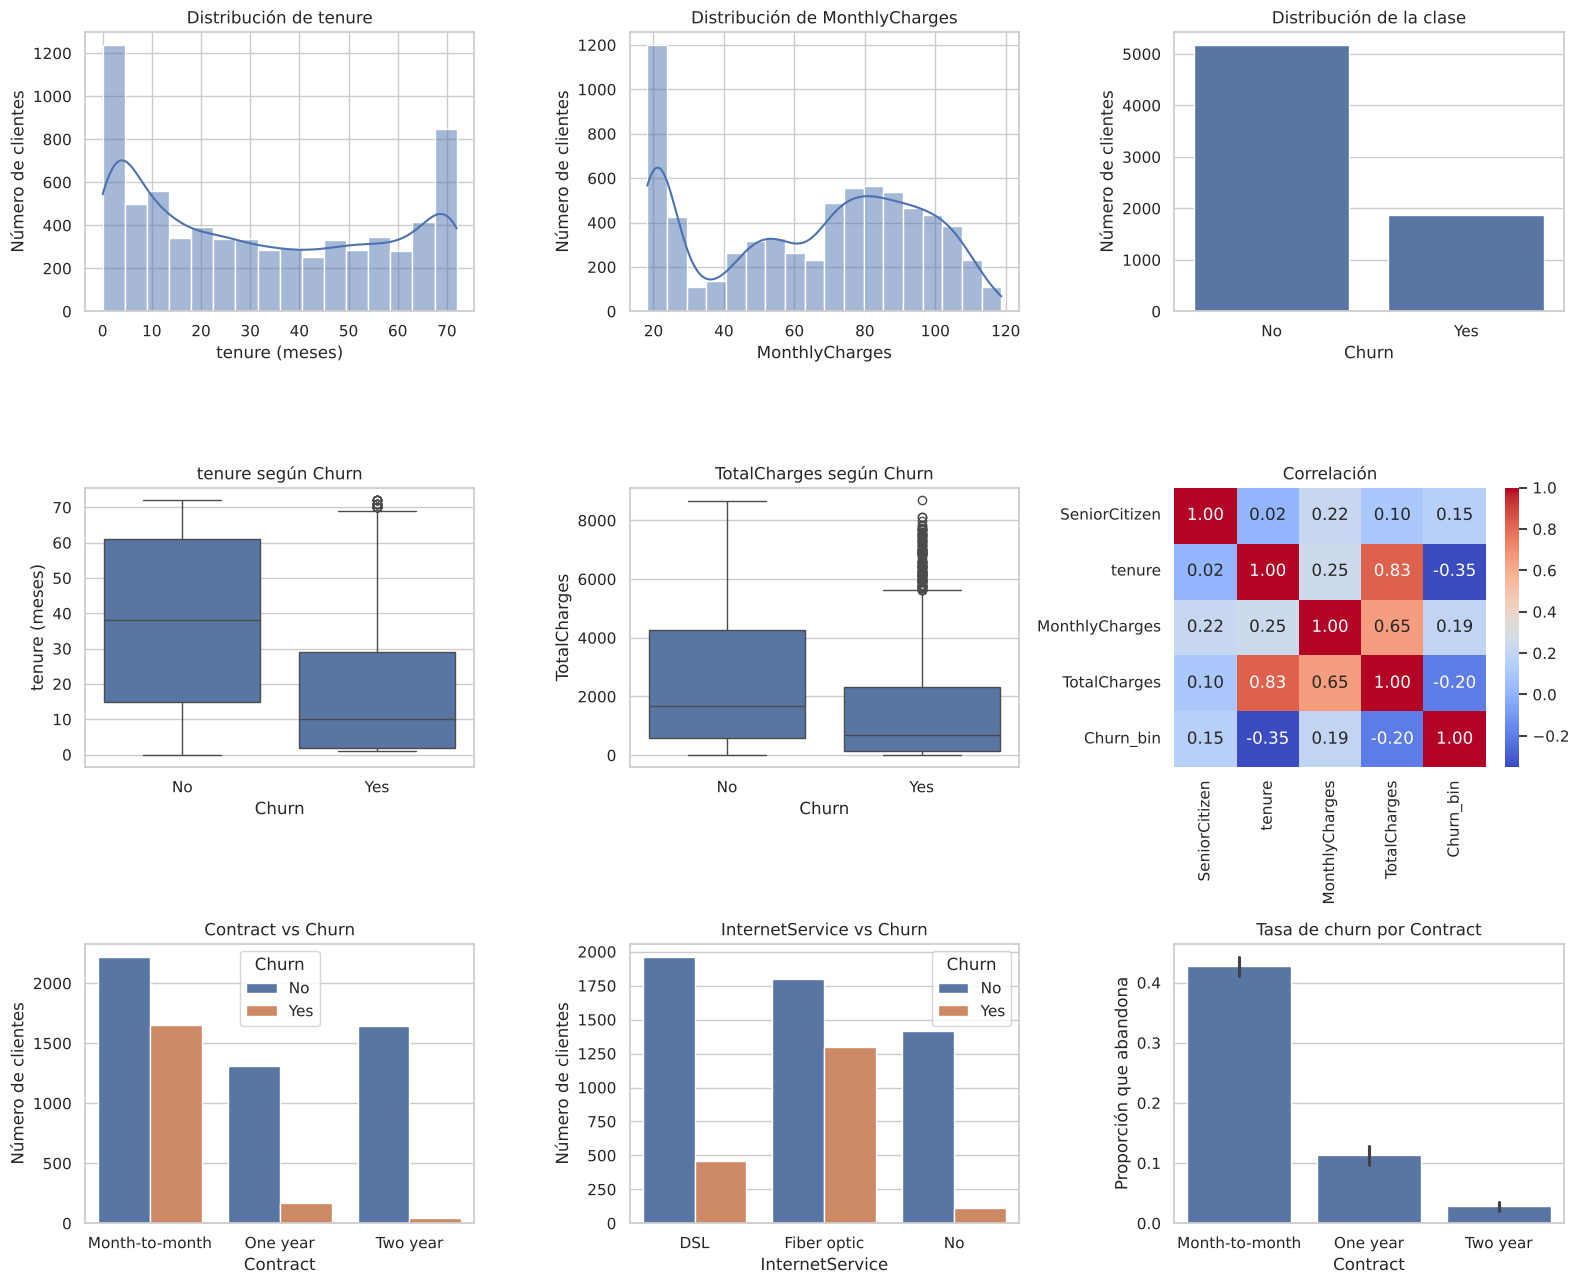

In [11]:
fig, ax = plt.subplots(3, 3, figsize=(16, 13))

sns.histplot(telco["tenure"], kde=True, ax=ax[0,0]); ax[0,0].set_title("Distribución de tenure")
sns.histplot(telco["MonthlyCharges"], kde=True, ax=ax[0,1]); ax[0,1].set_title("Distribución de MonthlyCharges")
sns.countplot(x="Churn", data=telco, ax=ax[0,2]); ax[0,2].set_title("Distribución de la clase")

sns.boxplot(x="Churn", y="tenure", data=telco, ax=ax[1,0]); ax[1,0].set_title("tenure según Churn")
sns.boxplot(x="Churn", y="TotalCharges", data=telco, ax=ax[1,1]); ax[1,1].set_title("TotalCharges según Churn")
sns.heatmap(telco[["SeniorCitizen","tenure","MonthlyCharges","TotalCharges","Churn_bin"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1,2]); ax[1,2].set_title("Correlación")

sns.countplot(x="Contract", hue="Churn", data=telco, ax=ax[2,0]); ax[2,0].set_title("Contract vs Churn")
sns.countplot(x="InternetService", hue="Churn", data=telco, ax=ax[2,1]); ax[2,1].set_title("InternetService vs Churn")
sns.barplot(x="Contract", y="Churn_bin", data=telco, ax=ax[2,2]); ax[2,2].set_title("Tasa de churn por Contract")

ax[0,0].set_xlabel("tenure (meses)"); ax[1,0].set_ylabel("tenure (meses)")
for a in [ax[0,0], ax[0,1], ax[0,2], ax[2,0], ax[2,1]]:
    a.set_ylabel("Número de clientes")
ax[2,2].set_ylabel("Proporción que abandona")

plt.tight_layout(); plt.show()

### Tasas exactas de abandono
Esta celda calcula las cifras que respaldan el hallazgo del EDA: tasa de abandono por tipo de contrato y de servicio de internet, y mediana de `tenure` y de los cargos según `Churn`.

In [12]:
print((telco.groupby("Contract")["Churn_bin"].mean() * 100).round(1), "\n")
print((telco.groupby("InternetService")["Churn_bin"].mean() * 100).round(1), "\n")
print(telco.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].median())

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn_bin, dtype: float64 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn_bin, dtype: float64 

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No       38.0          64.425       1683.60
Yes      10.0          79.650        703.55


### Interpretación del EDA de Telco
- **Distribución de `tenure`:** tiene forma de U: muchos clientes nuevos (1,371 con menos de 6 meses) y muchos muy antiguos (1,033 con 66 meses o más). No es una variable con outliers, sino con dos grupos de clientes.
- **Distribución de `MonthlyCharges`:** un pico muy marcado cerca de 20 (clientes sin internet) y el resto repartido entre ~45 y ~115, con otro pico alrededor de 80; tampoco presenta valores extremos.
- **Distribución de la clase:** 5,174 "No" contra 1,869 "Yes" (73.5 % vs. 26.5 %, IR = 2.77): un modelo que siempre dijera "No" ya tendría 73.5 % de accuracy.
- **Boxplot de `tenure`:** quienes abandonan llevan mucho menos tiempo (mediana 10 meses contra 38).
- **Boxplot de `TotalCharges`:** quienes abandonan acumulan menos (mediana 703.55 contra 1,683.60), pero es consecuencia de su menor antigüedad, no un efecto distinto. Los puntos por encima del bigote en el grupo "Yes" son clientes antiguos que se fueron, no errores.
- **Matriz de correlación:** `tenure` es la numérica más ligada al abandono (-0.35); `MonthlyCharges` tiene 0.19 y `SeniorCitizen` 0.15. Se confirma la redundancia `tenure`-`TotalCharges` (0.83).
- **`Contract` vs. `Churn`:** es la variable que más separa: 42.7 % de abandono en contrato mensual, 11.3 % a un año y 2.8 % a dos años.
- **`InternetService` vs. `Churn`:** fibra óptica 41.9 %, DSL 19.0 % y sin internet 7.4 %.

**Implicaciones:** las numéricas de Telco no requieren winsorización (se confirma con IQR en la sección 5); el problema principal es el desbalance, que obliga a evaluar con precision, recall y F1 además de accuracy.

## 4. Imputación de valores perdidos
Se separan los datos de Titanic en entrenamiento (80 %) y prueba (20 %) con estratificación **antes** de imputar, y todos los valores de imputación se calculan solo con entrenamiento (dentro de pipelines) para evitar fuga de información. El conjunto de prueba no se toca hasta la sección 7.

Variables elegidas: **`Age`** (numérica, 19.9 % de nulos) y **`Embarked`** (categórica, 2 nulos). `Cabin` no se imputa: con 77 % de nulos cualquier valor sería casi todo inventado, así que se excluye.

| Estrategia | `Age` (numérica) | `Embarked` (categórica) | Por qué es razonable |
|---|---|---|---|
| A | Media | Moda ("S") | Es la opción más simple; la media es adecuada porque `Age` es casi simétrica y la moda de `Embarked` concentra el 72 % de los casos. |
| B | Mediana | Categoría "Desconocido" | La mediana es robusta a valores extremos y "Desconocido" no inventa un puerto: deja que el modelo trate la ausencia como información propia. |
| B + indicador | Mediana + columna 0/1 de "edad ausente" | "Desconocido" | Sirve si el hecho de no tener la edad está relacionado con el objetivo. |

In [13]:
from sklearn.model_selection import train_test_split

X = titanic.drop(columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"])
X["Pclass"] = X["Pclass"].astype(str)   # es categórica
y = titanic["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print("Nulos en train:\n", X_train.isna().sum())

# ¿La ausencia de Age es informativa? (solo con entrenamiento)
print("\nTasa de supervivencia según si falta Age:")
print(y_train.groupby(X_train["Age"].isna()).agg(["mean", "size"]).rename(index={False: "Age presente", True: "Age ausente"}).round(3))
print("\nClase de los pasajeros con y sin Age (proporción por columna):")
print(pd.crosstab(X_train["Pclass"], X_train["Age"].isna(), normalize="columns").round(2))

(712, 7) (179, 7)
Nulos en train:
 Pclass        0
Sex           0
Age         137
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

Tasa de supervivencia según si falta Age:
               mean  size
Age                      
Age presente  0.405   575
Age ausente   0.292   137

Clase de los pasajeros con y sin Age (proporción por columna):
Age     False  True 
Pclass              
1        0.25   0.19
2        0.25   0.07
3        0.50   0.74


### Efecto de la imputación en la distribución de `Age` y `Embarked`
Se compara la distribución original (sin nulos) contra la imputada con media (A) y con mediana (B), revisando media, desviación estándar, asimetría y concentraciones artificiales. Para `Embarked` se comparan las frecuencias antes y después.

,count,mean,std,min,25%,50%,75%,max,varianza,asimetria,filas en el valor imputado
original (sin nulos),575.0,29.81,14.49,0.42,21.0,28.50,39.0,80.0,209.82,0.35,NaN
A: media,712.0,29.81,13.02,0.42,22.0,29.81,36.0,80.0,169.39,0.39,137.0
B: mediana,712.0,29.56,13.03,0.42,22.0,28.50,36.0,80.0,169.66,0.45,139.0


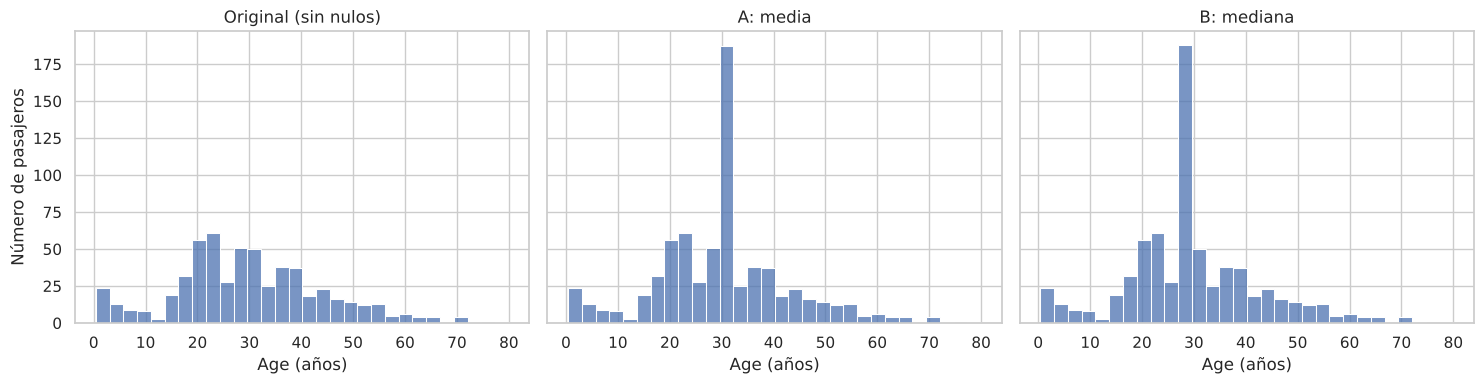

,original,A: moda,B: Desconocido
Embarked,,,
C,139,139,139
Desconocido,0,0,2
Q,55,55,55
S,516,518,516
NaN,2,0,0


In [14]:
age = X_train["Age"]
age_media = age.fillna(age.mean())
age_mediana = age.fillna(age.median())

comp = pd.DataFrame({
    "original (sin nulos)": age.dropna().describe(),
    "A: media": age_media.describe(),
    "B: mediana": age_mediana.describe(),
}).T
comp["varianza"] = [age.dropna().var(), age_media.var(), age_mediana.var()]
comp["asimetria"] = [age.dropna().skew(), age_media.skew(), age_mediana.skew()]
# Concentración artificial: cuántas filas quedan con exactamente el valor imputado
comp["filas en el valor imputado"] = [np.nan, (age_media == age.mean()).sum(), (age_mediana == age.median()).sum()]
display(comp.round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
sns.histplot(age.dropna(), bins=30, ax=ax[0]); ax[0].set_title("Original (sin nulos)")
sns.histplot(age_media, bins=30, ax=ax[1]); ax[1].set_title("A: media")
sns.histplot(age_mediana, bins=30, ax=ax[2]); ax[2].set_title("B: mediana")
for a in ax:
    a.set_xlabel("Age (años)")
ax[0].set_ylabel("Número de pasajeros")
plt.tight_layout(); plt.show()

# Embarked: frecuencias antes y después de imputar
emb = X_train["Embarked"]
display(pd.DataFrame({
    "original": emb.value_counts(dropna=False),
    "A: moda": emb.fillna(emb.mode()[0]).value_counts(),
    "B: Desconocido": emb.fillna("Desconocido").value_counts(),
}).fillna(0).astype(int))

### Efecto de la imputación en el desempeño
Se evalúan las tres estrategias dentro de un pipeline con validación cruzada estratificada de 5 folds sobre el entrenamiento (el imputador se ajusta solo con los folds de entrenamiento de cada partición). Se reportan accuracy, precision, recall, F1 y ROC-AUC (promedio de los 5 folds) y la desviación estándar del F1 entre folds, para saber qué diferencias son relevantes.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold

num_cols = ["Age", "SibSp", "Parch", "Fare"]
cat_cols = ["Sex", "Embarked", "Pclass"]

cv = StratifiedKFold(5, shuffle=True, random_state=42)
METRICAS = ["accuracy", "precision", "recall", "f1", "roc_auc"]

def evaluar_cv(modelo, X, y):
    # Promedio de cada métrica en los 5 folds + desviación del F1 entre folds
    r = cross_validate(modelo, X, y, cv=cv, scoring=METRICAS)
    resultado = {m: round(r[f"test_{m}"].mean(), 3) for m in METRICAS}
    resultado["f1_desv"] = round(r["test_f1"].std(), 3)
    return resultado

def build(num_strategy, cat_strategy, indicator=False):
    num = Pipeline([("imp", SimpleImputer(strategy=num_strategy, add_indicator=indicator)),
                    ("sc", StandardScaler())])
    if cat_strategy == "moda":
        cat_imp = SimpleImputer(strategy="most_frequent")
    else:
        cat_imp = SimpleImputer(strategy="constant", fill_value="Desconocido")
    cat = Pipeline([("imp", cat_imp), ("oh", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])

estrategias = {
    "A: media + moda": ("mean", "moda", False),
    "B: mediana + Desconocido": ("median", "desconocido", False),
    "B + indicador de ausente": ("median", "desconocido", True),
}

filas = []
for nombre, (ns, cs, ind) in estrategias.items():
    filas.append({"estrategia": nombre, **evaluar_cv(build(ns, cs, ind), X_train, y_train)})
display(pd.DataFrame(filas))

,estrategia,accuracy,precision,recall,f1,roc_auc,f1_desv
0,A: media + moda,0.801,0.762,0.700,0.729,0.853,0.023
1,B: mediana + Desconocido,0.802,0.765,0.700,0.730,0.853,0.022
2,B + indicador de ausente,0.796,0.759,0.692,0.723,0.853,0.027


### Conclusión de la imputación
**Variables y valores faltantes iniciales (entrenamiento, 712 filas):** `Age` 137 nulos (19.2 %) y `Embarked` 2 nulos.

**Cambio en la distribución y la varianza.**
- Ambas estrategias meten los 137 valores en un solo número: la media (29.81) en A y la mediana (28.5) en B. Eso crea un **pico artificial** que se ve en los histogramas (137 filas en 29.81 con A y 139 en 28.5 con B, porque ya había 2 pasajeros con esa edad).
- La desviación estándar de `Age` baja de 14.49 a 13.02 (A) y 13.03 (B), alrededor de 10 %, y la varianza baja casi 20 % (209.8 a ~169.5). El rango intercuartílico también se estrecha (de 21-39 a 22-36). La media no cambia con A y baja un poco con B (29.56); la asimetría sube ligeramente (0.35 a 0.39 y 0.45).
- En `Embarked` el efecto es mínimo: con A los 2 casos se suman a "S" (516 a 518) y con B se crea una categoría "Desconocido" con 2 filas.

**Desempeño del clasificador.** A (accuracy 0.801, F1 0.729) y B (0.802, 0.730) son prácticamente iguales y tienen el mismo ROC-AUC (0.853). Las diferencias (0.007 o menos) son mucho menores que la variación del F1 entre folds (~0.022), así que no son relevantes.

**Indicador de ausente.** La ausencia sí parece informativa: sobrevivió el 29.2 % de los pasajeros sin edad registrada contra el 40.5 % de los que sí la tienen. Aun así, el indicador no mejoró el modelo (F1 0.723). Una explicación probable es que la mayoría de los pasajeros sin edad viajaban en tercera clase (ver la tabla de arriba), así que esa información ya la aporta `Pclass`.

**Decisión:** estrategia B (mediana + "Desconocido"), sin indicador. Rinde igual que A, la mediana es robusta si la variable tiene valores extremos y "Desconocido" no inventa un puerto. Tenemos claro su costo: reduce la varianza y crea un pico artificial en `Age`, por lo que conviene no sacar conclusiones sobre la distribución de edades a partir de los datos imputados. `Cabin` (77 % de nulos) no se imputa.

## 5. Detección y winsorización de outliers
Primero se detectan outliers con el criterio IQR (fuera de [Q1 - 1.5·IQR, Q3 + 1.5·IQR]) en todas las numéricas de ambos datasets, para decidir a cuál conviene aplicar winsorización. Esta revisión es solo exploratoria; los límites que se usan para transformar se calculan después, solo con entrenamiento.

In [16]:
def contar_outliers_iqr(df, columnas):
    filas = []
    for c in columnas:
        q1, q3 = df[c].quantile([0.25, 0.75])
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        n = ((df[c] < lo) | (df[c] > hi)).sum()
        filas.append({"variable": c, "Q1": q1, "Q3": q3, "límite inf": lo, "límite sup": hi,
                      "outliers": n, "%": n / df[c].notna().sum() * 100})
    return pd.DataFrame(filas).set_index("variable").round(2)

display(contar_outliers_iqr(titanic, ["Age", "SibSp", "Parch", "Fare"]))
display(contar_outliers_iqr(telco, ["tenure", "MonthlyCharges", "TotalCharges"]))

,Q1,Q3,límite inf,límite sup,outliers,%
variable,,,,,,
Age,20.12,38.0,-6.69,64.81,11,1.54
SibSp,0.00,1.0,-1.50,2.50,46,5.16
Parch,0.00,0.0,0.00,0.00,213,23.91
Fare,7.91,31.0,-26.72,65.63,116,13.02


,Q1,Q3,límite inf,límite sup,outliers,%
variable,,,,,,
tenure,9.00,55.00,-60.00,124.00,0,0.0
MonthlyCharges,35.50,89.85,-46.02,171.38,0,0.0
TotalCharges,401.45,3794.74,-4688.48,8884.67,0,0.0


**¿A qué variable se aplica?** A `Fare`:
- Es continua, muy asimétrica (4.79) y tiene valores muy alejados (hasta 512.33).
- `SibSp` y `Parch` son conteos pequeños; en `Parch` el Q1 y el Q3 valen 0, así que el IQR marca como "outlier" a cualquier pasajero que viaje con familia. Recortarlas borraría información real, no errores.
- `Age` solo tiene 11 casos marcados (edades de 66 a 80, que son plausibles).
- En Telco, el IQR no detecta outliers en `tenure`, `MonthlyCharges` ni `TotalCharges`, lo cual también es un resultado válido: no hay nada que winsorizar.

Se comparan dos criterios para `Fare`, ambos con límites calculados **solo con entrenamiento**:
1. **IQR:** se recorta a [Q1 - 1.5·IQR, Q3 + 1.5·IQR].
2. **Percentiles 1 y 99:** todo valor por debajo del percentil 1 se sube al percentil 1 y todo valor por encima del percentil 99 se baja al percentil 99. Es decir, solo se modifica el 1 % más bajo y el 1 % más alto.

La winsorización no elimina filas: solo reemplaza los valores extremos por el límite. Se aplica sobre una copia (`X_train` no se modifica).

iqr: límites = [-26.76, 65.66] | recortados = 91 (12.8%)
pct: límites = [0.00, 227.53] | recortados = 7 (1.0%)


,media,mediana,desv_est,min,max,asimetria
ninguno,31.82,14.45,48.06,0.0,512.33,4.65
iqr,23.96,14.45,20.51,0.0,65.66,1.08
pct,30.82,14.45,41.00,0.0,227.52,2.93


Máximo de Fare en X_train (sin cambios): 512.3292


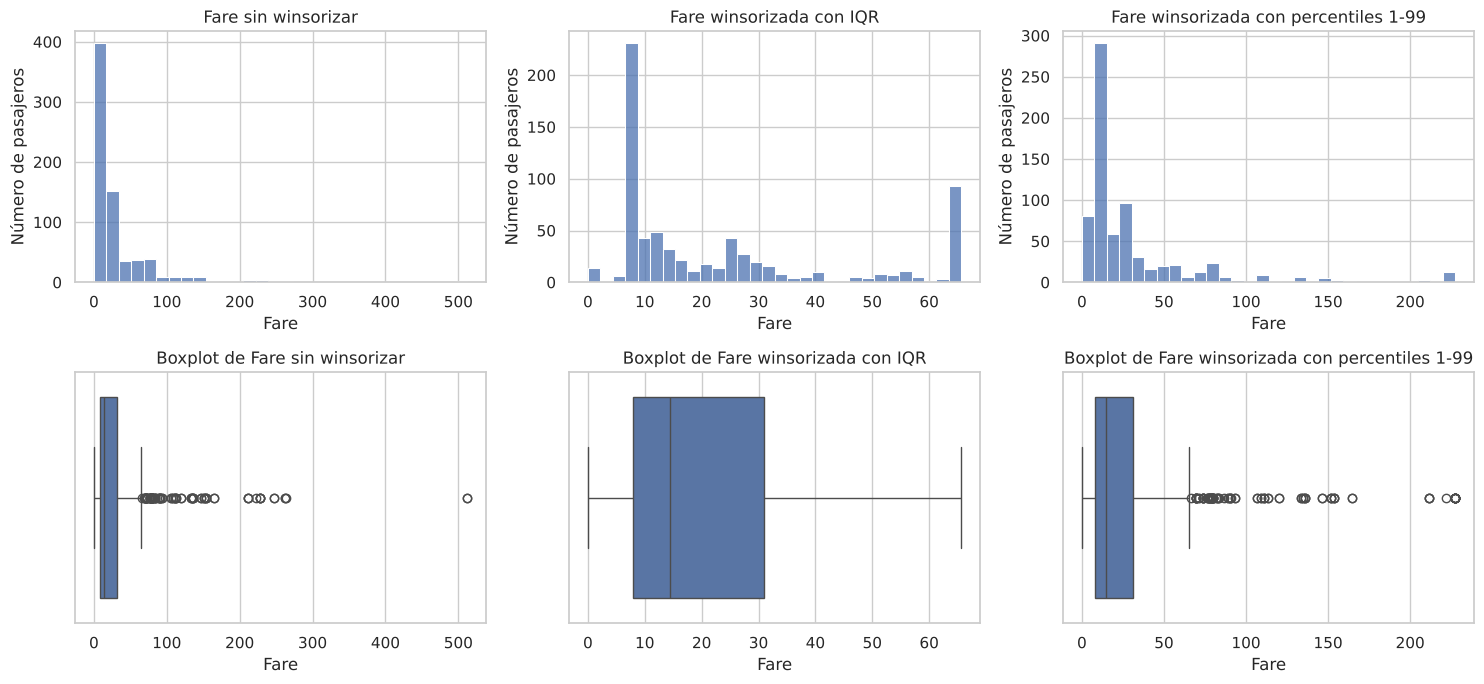

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, metodo="ninguno", k=1.5, p=(0.01, 0.99)):
        self.metodo, self.k, self.p = metodo, k, p
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        if self.metodo == "iqr":
            q1, q3 = np.nanpercentile(X, [25, 75], axis=0)
            self.lo_, self.hi_ = q1 - self.k*(q3-q1), q3 + self.k*(q3-q1)
        elif self.metodo == "pct":
            self.lo_, self.hi_ = np.nanpercentile(X, [self.p[0]*100, self.p[1]*100], axis=0)
        else:
            self.lo_, self.hi_ = np.full(X.shape[1], -np.inf), np.full(X.shape[1], np.inf)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)

fare = X_train[["Fare"]]
versiones = {}
for m in ["ninguno", "iqr", "pct"]:
    w = Winsorizer(m).fit(fare)
    versiones[m] = pd.Series(w.transform(fare).ravel())
    if m != "ninguno":
        n_rec = ((fare["Fare"] < w.lo_[0]) | (fare["Fare"] > w.hi_[0])).sum()
        print(f"{m}: límites = [{w.lo_[0]:.2f}, {w.hi_[0]:.2f}] | recortados = {n_rec} ({n_rec/len(fare)*100:.1f}%)")

tabla = pd.DataFrame({k: v.describe()[["mean","50%","std","min","max"]] for k, v in versiones.items()}).T
tabla.columns = ["media", "mediana", "desv_est", "min", "max"]
tabla["asimetria"] = [v.skew() for v in versiones.values()]
display(tabla.round(2))
print("Máximo de Fare en X_train (sin cambios):", X_train["Fare"].max())

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
titulos = {"ninguno": "sin winsorizar", "iqr": "winsorizada con IQR", "pct": "winsorizada con percentiles 1-99"}
for i, (m, v) in enumerate(versiones.items()):
    sns.histplot(v, bins=30, ax=ax[0, i]); ax[0, i].set_title(f"Fare {titulos[m]}")
    ax[0, i].set_xlabel("Fare"); ax[0, i].set_ylabel("Número de pasajeros")
    sns.boxplot(x=v, ax=ax[1, i]); ax[1, i].set_title(f"Boxplot de Fare {titulos[m]}")
    ax[1, i].set_xlabel("Fare")
plt.tight_layout(); plt.show()

### Efecto de la winsorización en el desempeño
Se entrena el mismo modelo (imputación B) con `Fare` sin winsorizar, winsorizada por IQR y winsorizada por percentiles 1 y 99. El winsorizador está dentro del pipeline, así que sus límites se calculan solo con los folds de entrenamiento.

In [18]:
def build_w(metodo):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    fare_p = Pipeline([("w", Winsorizer(metodo)), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Desconocido")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    pre = ColumnTransformer([("num", num, ["Age", "SibSp", "Parch"]),
                             ("fare", fare_p, ["Fare"]),
                             ("cat", cat, ["Sex", "Embarked", "Pclass"])])
    return Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])

filas = []
for m in ["ninguno", "iqr", "pct"]:
    filas.append({"winsor": m, **evaluar_cv(build_w(m), X_train, y_train)})
display(pd.DataFrame(filas))

,winsor,accuracy,precision,recall,f1,roc_auc,f1_desv
0,ninguno,0.802,0.765,0.700,0.730,0.853,0.022
1,iqr,0.788,0.742,0.689,0.713,0.856,0.025
2,pct,0.802,0.765,0.700,0.730,0.852,0.022


### Conclusión de la winsorización
**Límites usados (calculados con entrenamiento):**
- **IQR:** [-26.76, 65.66]. El límite inferior es negativo, así que solo actúa el superior: 91 tarifas (12.8 %) se bajan a 65.66.
- **Percentiles 1 y 99:** [0.00, 227.53]. El percentil 1 es 0, así que tampoco cambia nada abajo (los 15 `Fare = 0` se conservan); solo las 7 tarifas más altas (1.0 %) se bajan a ~227.5.

**Antes vs. después:**

| | Media | Mediana | Desv. est. | Mín. | Máx. | Asimetría |
|---|---|---|---|---|---|---|
| Sin winsorizar | 31.82 | 14.45 | 48.06 | 0 | 512.33 | 4.65 |
| IQR | 23.96 | 14.45 | 20.51 | 0 | 65.66 | 1.08 |
| Percentiles 1-99 | 30.82 | 14.45 | 41.00 | 0 | 227.53 | 2.93 |

La mediana no cambia en ningún caso, como se espera. El IQR cambia mucho la variable (la media baja 25 % y la desviación más de la mitad); los percentiles solo recortan la cola extrema.

**Desempeño:** sin winsorizar y con percentiles se obtiene lo mismo (accuracy 0.802, F1 0.730). Con IQR el desempeño baja (accuracy 0.788, F1 0.713), aunque su ROC-AUC es apenas mayor (0.856 vs. 0.853). Es decir, **la winsorización no mejoró el clasificador** en ninguno de los dos criterios.

**Decisión:** percentiles 1 y 99. No es por desempeño, sino porque reduce la influencia de los valores más extremos (el máximo pasa de 512 a 227 y la asimetría de 4.65 a 2.93) sin perder información. El IQR no es adecuado para `Fare`: con una distribución tan sesgada marca como outlier al 12.8 % de los pasajeros, que en su mayoría son tarifas legítimas de primera clase y no errores de captura.

## 6. Tratamiento del desbalance
Para cada dataset se calcula la cantidad y el porcentaje de observaciones por clase y la razón de desbalance:

$$IR = \frac{N_{mayoritaria}}{N_{minoritaria}}$$

Según el criterio de la práctica, si IR > 1.5 el dataset se considera desbalanceado. El IR se calcula a partir de los conteos reales, no se escribe a mano.

In [19]:
def resumen_desbalance(y, etiquetas):
    conteo = y.value_counts()
    tabla = pd.DataFrame({"n": conteo, "%": (conteo / len(y) * 100).round(1)})
    tabla.index = [etiquetas[v] for v in tabla.index]
    display(tabla)
    n_may, n_min = tabla["n"].max(), tabla["n"].min()
    IR = n_may / n_min
    print(f"Clase mayoritaria: {tabla['n'].idxmax()} | Clase minoritaria: {tabla['n'].idxmin()}")
    print(f"IR = {n_may} / {n_min} = {IR:.2f} ->",
          "desbalanceado (IR > 1.5)" if IR > 1.5 else "no desbalanceado (IR <= 1.5)")
    return IR

print("TITANIC")
IR_titanic = resumen_desbalance(titanic["Survived"], {0: "No sobrevivió", 1: "Sobrevivió"})
print("\nTELCO")
IR_telco = resumen_desbalance(telco["Churn"], {"No": "No abandona", "Yes": "Abandona"})

TITANIC


,n,%
No sobrevivió,549,61.6
Sobrevivió,342,38.4


Clase mayoritaria: No sobrevivió | Clase minoritaria: Sobrevivió
IR = 549 / 342 = 1.61 -> desbalanceado (IR > 1.5)

TELCO


,n,%
No abandona,5174,73.5
Abandona,1869,26.5


Clase mayoritaria: No abandona | Clase minoritaria: Abandona
IR = 5174 / 1869 = 2.77 -> desbalanceado (IR > 1.5)


**Interpretación.** **Ambos datasets superan el umbral de 1.5**, así que los dos se consideran desbalanceados según el criterio de la práctica:
- **Titanic:** IR = 1.61. Lo supera por poco: es un desbalance leve (61.6 % vs. 38.4 %).
- **Telco:** IR = 2.77. Es un desbalance moderado y, además, la clase que interesa detectar (los clientes que se van) es la minoritaria.

**¿Por qué el análisis completo se hace en Telco?** Las cinco estrategias se comparan a fondo en Telco porque ahí el desbalance es más fuerte y tiene una lectura de negocio clara (detectar abandonos vs. generar falsas alarmas). Como Titanic también supera el umbral, al final de esta sección se hace una comprobación breve con las mismas cinco estrategias para ver si el balanceo cambia algo en un desbalance leve.

Estrategias comparadas:

| Estrategia | Cómo funciona | Riesgo principal |
|---|---|---|
| Sin balanceo | Línea base: se entrena con la distribución original | Que el modelo ignore la clase minoritaria |
| Ponderación de clases | `class_weight="balanced"`: los errores en la clase minoritaria cuestan más en la función de pérdida, sin cambiar los datos | Las probabilidades quedan descalibradas (requiere calibración si se usan como probabilidades reales) |
| Sobremuestreo aleatorio | Replica al azar filas de la clase minoritaria hasta igualar las clases | Sobreajuste a esos casos repetidos |
| Submuestreo aleatorio | Elimina al azar filas de la clase mayoritaria hasta igualar las clases | Pérdida de información |
| SMOTE | Crea ejemplos sintéticos interpolando entre un caso minoritario y sus vecinos más cercanos | Casos artificiales poco plausibles (sobre todo con variables categóricas codificadas) |

El sobremuestreo, el submuestreo y SMOTE se aplican **solo sobre los datos de entrenamiento**: van dentro de un pipeline de `imblearn`, que los ejecuta únicamente al entrenar cada fold y nunca al evaluar. El conjunto de prueba conserva su distribución original.

### Preparación de Telco para el modelado
- Se elimina `customerID` (identificador) y, por supuesto, `Churn` y `Churn_bin` (objetivo).
- Se unifican "No internet service" y "No phone service" con "No" (es una regla fija, no aprende nada de los datos, así que no genera fuga).
- `SeniorCitizen` se trata como categórica.
- Se separa 80 % entrenamiento y 20 % prueba con estratificación. **La misma partición y los mismos 5 folds se usan para las cinco estrategias**, para que la comparación sea justa.
- El preprocesador (mediana y escalado para numéricas, one-hot para categóricas) se ajusta dentro del pipeline, solo con entrenamiento.

In [20]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

T = telco.drop(columns=["customerID", "Churn", "Churn_bin"]).copy()
T = T.replace({"No internet service": "No", "No phone service": "No"})
T["SeniorCitizen"] = T["SeniorCitizen"].astype(str)
t = telco["Churn_bin"]

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    T, t, test_size=0.2, stratify=t, random_state=42)

num_t = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_t = [c for c in T.columns if c not in num_t]

pre_t = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_t),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_t)])

print("Entrenamiento:", Xt_train.shape, "| Prueba:", Xt_test.shape)
print("Proporción de abandono -> train:", round(yt_train.mean(), 3), "| test:", round(yt_test.mean(), 3))

Entrenamiento: (5634, 19) | Prueba: (1409, 19)
Proporción de abandono -> train: 0.265 | test: 0.265


### Comparación de las cinco estrategias en Telco
Para cada estrategia se calculan accuracy, precision, recall, F1 y ROC-AUC con validación cruzada de 5 folds sobre el entrenamiento. Precision, recall y F1 se refieren siempre a la clase minoritaria (abandona = 1).

In [21]:
def build_bal(nombre, pre):
    clf = LogisticRegression(max_iter=1000,
          class_weight="balanced" if nombre == "Ponderación de clases" else None)
    sampler = {"Sobremuestreo aleatorio": RandomOverSampler(random_state=42),
               "Submuestreo aleatorio": RandomUnderSampler(random_state=42),
               "SMOTE": SMOTE(random_state=42)}.get(nombre)
    pasos = [("pre", pre)] + ([("samp", sampler)] if sampler else []) + [("clf", clf)]
    return ImbPipeline(pasos)

nombres = ["Sin balanceo", "Ponderación de clases", "Sobremuestreo aleatorio",
           "Submuestreo aleatorio", "SMOTE"]

# Cuántas filas de entrenamiento ve el modelo con cada técnica de remuestreo (ejemplo con todo el train)
Xt_pre = pre_t.fit_transform(Xt_train)
for n in ["Sobremuestreo aleatorio", "Submuestreo aleatorio", "SMOTE"]:
    _, y_res = build_bal(n, pre_t).named_steps["samp"].fit_resample(Xt_pre, yt_train)
    print(f"{n:24s} -> clases en entrenamiento: {y_res.value_counts().to_dict()}")
print(f"{'Original':24s} -> clases en entrenamiento: {yt_train.value_counts().to_dict()}\n")

filas = []
for n in nombres:
    filas.append({"estrategia": n, **evaluar_cv(build_bal(n, pre_t), Xt_train, yt_train)})
res_telco = pd.DataFrame(filas)
display(res_telco)

Sobremuestreo aleatorio  -> clases en entrenamiento: {0: 4139, 1: 4139}
Submuestreo aleatorio    -> clases en entrenamiento: {0: 1495, 1: 1495}
SMOTE                    -> clases en entrenamiento: {0: 4139, 1: 4139}
Original                 -> clases en entrenamiento: {0: 4139, 1: 1495}



,estrategia,accuracy,precision,recall,f1,roc_auc,f1_desv
0,Sin balanceo,0.802,0.653,0.542,0.592,0.846,0.030
1,Ponderación de clases,0.749,0.518,0.803,0.629,0.846,0.022
2,Sobremuestreo aleatorio,0.748,0.516,0.802,0.628,0.846,0.018
3,Submuestreo aleatorio,0.746,0.514,0.800,0.626,0.846,0.017
4,SMOTE,0.756,0.528,0.791,0.633,0.845,0.021


### Conclusión del balanceo en Telco
- **Por qué no basta la accuracy:** el modelo sin balanceo tiene la accuracy más alta (0.802), pero un modelo que siempre dijera "No abandona" ya tendría 0.735, y el modelo base solo detecta al 54 % de los clientes que se van (recall 0.542). Si se eligiera por accuracy, se escogería el modelo que más abandonos deja pasar.
- **Efecto del balanceo:** las cuatro técnicas suben el recall de 0.54 a cerca de 0.80 a cambio de bajar la precision de 0.65 a ~0.52; el F1 mejora de 0.592 a 0.626-0.633, una diferencia mayor que la variación entre folds (~0.02-0.03). El ROC-AUC no cambia (0.845-0.846): el balanceo **mueve el punto de corte**, pero no mejora la capacidad del modelo de ordenar a los clientes por riesgo.
- **Entre técnicas:** rinden casi igual. SMOTE tiene el F1 más alto (0.633) y la ponderación el recall más alto (0.803), pero las diferencias (menos de 0.01) están dentro de la variación entre folds.

| Estrategia | Resultado (CV) | Lectura |
|---|---|---|
| Sin balanceo | F1 0.592, recall 0.542, precision 0.653 | Es la más precisa, pero deja pasar casi la mitad de los abandonos |
| Ponderación de clases | F1 0.629, recall 0.803, precision 0.518 | Mismo efecto que remuestrear, sin tocar los datos |
| Sobremuestreo aleatorio | F1 0.628, recall 0.802, precision 0.516 | Igual a la ponderación; duplica 2,644 filas minoritarias en el entrenamiento |
| Submuestreo aleatorio | F1 0.626, recall 0.800, precision 0.514 | Rinde casi igual, pero descarta 2,644 clientes que no abandonaron |
| SMOTE | F1 0.633, recall 0.791, precision 0.528 | El mejor F1 por muy poco, a costa de crear clientes sintéticos (interpolando columnas one-hot) |

**Decisión:** ponderación de clases. Con un rendimiento equivalente, es la más simple y la única que no duplica, inventa ni descarta registros. La métrica que guía la elección es el **F1 y el recall de la clase "abandona"**, no la accuracy, porque el objetivo del negocio es detectar a los clientes que se van.

### Balanceo en Titanic
Como Titanic también supera el umbral (IR = 1.61), se aplican las mismas cinco estrategias con el preprocesamiento elegido en las secciones 4 y 5 (mediana + "Desconocido" y winsorización por percentiles 1-99).

In [22]:
pre_titanic = build_w("pct")["pre"]   # preprocesador elegido para Titanic

filas = []
for n in nombres:
    filas.append({"estrategia": n, **evaluar_cv(build_bal(n, pre_titanic), X_train, y_train)})
display(pd.DataFrame(filas))

,estrategia,accuracy,precision,recall,f1,roc_auc,f1_desv
0,Sin balanceo,0.802,0.765,0.700,0.730,0.852,0.022
1,Ponderación de clases,0.784,0.703,0.762,0.730,0.853,0.038
2,Sobremuestreo aleatorio,0.780,0.698,0.759,0.726,0.856,0.034
3,Submuestreo aleatorio,0.780,0.700,0.751,0.724,0.853,0.034
4,SMOTE,0.784,0.703,0.758,0.729,0.850,0.039


**Interpretación en Titanic.** Con un desbalance leve (IR = 1.61), las técnicas de balanceo suben el recall de 0.700 a ~0.76 y bajan la precision de 0.765 a ~0.70, pero el F1 no cambia (0.724-0.730) y el ROC-AUC tampoco (0.850-0.856). Además, la variación entre folds aumenta. Como no hay una razón para priorizar el recall de los sobrevivientes en un análisis histórico, **en Titanic se mantiene el modelo sin balanceo**. Esto confirma que superar el umbral de 1.5 no implica que balancear sea necesario: la decisión depende de qué tan fuerte es el desbalance y de qué error cuesta más.

## 7. Evaluación final en el conjunto de prueba
**Medidas para evitar fuga de información:**
1. El objetivo está claramente separado (`y` / `t`) y nunca entra como atributo. Se excluyen los identificadores (`PassengerId`, `Name`, `Ticket`, `customerID`) y `Cabin`.
2. La partición entrenamiento/prueba se hace antes de imputar, escalar, codificar, winsorizar o balancear.
3. Imputación, escalado, one-hot y winsorización viven dentro de pipelines: en la validación cruzada se ajustan con los folds de entrenamiento, y en esta sección con todo el entrenamiento.
4. El remuestreo (sobremuestreo, submuestreo, SMOTE) solo actúa al entrenar, nunca sobre la prueba.
5. El conjunto de prueba se usa **una sola vez**, aquí, con las estrategias ya elegidas en las secciones anteriores. Todas las métricas usan las mismas definiciones (precision, recall y F1 de la clase positiva) y el umbral por defecto de 0.5.

En Telco se comparan en prueba el modelo sin balanceo (referencia) y el de ponderación de clases (estrategia elegida). Como referencia, predecir siempre "No" da 73.5 % de accuracy.

Accuracy de predecir siempre 'No': 0.735
Clientes en prueba: 1409 | abandonos reales: 374


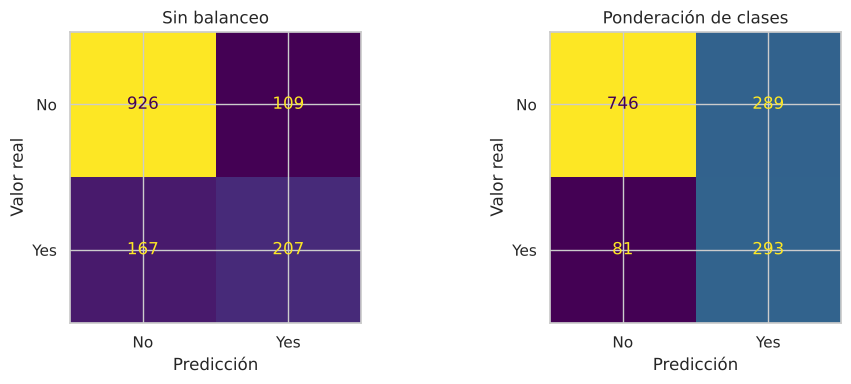

,accuracy,precision,recall,f1,roc_auc,VP,FP,FN,VN
modelo,,,,,,,,,
Sin balanceo,0.804,0.655,0.553,0.600,0.842,207,109,167,926
Ponderación de clases,0.737,0.503,0.783,0.613,0.842,293,289,81,746


In [23]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

def metricas_prueba(modelo, X, y):
    pred = modelo.predict(X)
    prob = modelo.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, prob), "VP": tp, "FP": fp, "FN": fn, "VN": tn}

print("Accuracy de predecir siempre 'No':", round(1 - yt_test.mean(), 3))
print("Clientes en prueba:", len(yt_test), "| abandonos reales:", yt_test.sum())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
filas = []
for a, n in zip(ax, ["Sin balanceo", "Ponderación de clases"]):
    modelo = build_bal(n, pre_t).fit(Xt_train, yt_train)
    filas.append({"modelo": n, **metricas_prueba(modelo, Xt_test, yt_test)})
    ConfusionMatrixDisplay.from_predictions(yt_test, modelo.predict(Xt_test),
                                            display_labels=["No", "Yes"], ax=a, colorbar=False)
    a.set_title(n); a.set_xlabel("Predicción"); a.set_ylabel("Valor real")
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).set_index("modelo").round(3))

En Titanic se evalúa en prueba el pipeline elegido (mediana + "Desconocido", winsorización por percentiles 1-99, sin balanceo) contra la referencia de predecir siempre "no sobrevivió".

In [24]:
modelo_titanic = build_w("pct").fit(X_train, y_train)
print("Accuracy de predecir siempre 0 (no sobrevivió):", round(1 - y_test.mean(), 3))
display(pd.DataFrame([metricas_prueba(modelo_titanic, X_test, y_test)], index=["Titanic (prueba)"]).round(3))

Accuracy de predecir siempre 0 (no sobrevivió): 0.615


,accuracy,precision,recall,f1,roc_auc,VP,FP,FN,VN
Titanic (prueba),0.804,0.793,0.667,0.724,0.842,46,12,23,98


**Resultados en prueba.**
- **Telco (1,409 clientes, 374 abandonos reales):** sin balanceo se detectan 207 abandonos (recall 0.553, precision 0.655, 109 falsas alarmas, accuracy 0.804). Con ponderación de clases se detectan 293 (recall 0.783, precision 0.503, 289 falsas alarmas, accuracy 0.737). Es decir, **86 abandonos más detectados a cambio de 180 falsas alarmas más** (unas 2 falsas alarmas por cada abandono adicional detectado). El F1 sube de 0.600 a 0.613 y el ROC-AUC es igual (0.842).
- **Titanic (179 pasajeros):** accuracy 0.804, precision 0.793, recall 0.667, F1 0.724 y ROC-AUC 0.842, contra 0.615 de accuracy de la referencia trivial.
- En ambos datasets las métricas de prueba son muy parecidas a las de validación cruzada, lo que indica que no hubo sobreajuste en la selección de estrategias.

## 8. Conclusiones
**1. Problemas de calidad detectados**
- **Titanic:** ausentes en `Age` (19.9 %), `Cabin` (77.1 %) y `Embarked` (2 filas); `Fare` muy asimétrica (4.79) con valores de hasta 512.33 y 15 tarifas en 0; identificadores (`PassengerId`, `Name`, `Ticket`) y una variable categórica codificada como número (`Pclass`). No hay duplicados, columnas constantes, etiquetas inconsistentes ni valores fuera de dominio.
- **Telco:** `TotalCharges` venía como texto y escondía 11 vacíos (0.16 %), todos de clientes con `tenure = 0`; categorías redundantes ("No internet service", "No phone service"); `TotalCharges` casi derivada de `tenure x MonthlyCharges` (correlación 0.83 con `tenure`); `SeniorCitizen` codificada como 0/1; desbalance moderado (IR = 2.77). No hay outliers según IQR, duplicados ni valores fuera de dominio.

**2. Decisiones de imputación y winsorización**
- **Imputación:** mediana para `Age` y "Desconocido" para `Embarked` (estrategia B). Rinde igual que media + moda, es robusta y no inventa categorías; su costo es que reduce ~10 % la desviación estándar y crea un pico artificial en la mediana. En Telco, los 11 `TotalCharges` vacíos se imputan con la mediana dentro del pipeline.
- **Winsorización:** percentiles 1 y 99 sobre `Fare`. Solo modifica el 1 % de las filas, conserva el desempeño y reduce el máximo y la asimetría. El IQR se descartó porque recorta el 12.8 % de tarifas legítimas y bajó el F1. Ninguno de los dos criterios mejoró el clasificador.

**3. Técnicas de balanceo**
- Ambos datasets superan el umbral IR > 1.5: Titanic por poco (1.61) y Telco con más margen (2.77).
- En Telco, las cuatro técnicas suben el recall de 0.54 a ~0.80 y el F1 de 0.59 a ~0.63 frente a la línea base; entre ellas la diferencia es menor a 0.01 (SMOTE tiene el F1 más alto por muy poco, la ponderación el recall más alto). El ROC-AUC no cambia.
- En Titanic, el balanceo no mejora el F1, así que no aporta.

**4. Limitaciones**
- Se usó un solo modelo (regresión logística) y el umbral por defecto de 0.5; otro modelo o un ajuste del umbral podría cambiar la comparación.
- Diferencias menores a la variación entre folds (~0.02 en F1) no deben interpretarse como mejoras reales.
- La recomendación de balanceo supone que perder un cliente cuesta más que contactar a uno de más; no se tienen datos de costos para comprobarlo.
- Telco es un dataset de ejemplo, de una sola foto en el tiempo; `tenure` y los cargos se miden al momento de la baja, lo que en un escenario real podría inflar el desempeño.
- Titanic es pequeño (891 filas) y refleja un evento histórico con sesgos de sexo y clase; en Telco, `gender` y `SeniorCitizen` son atributos sensibles que habría que auditar antes de usar el modelo.

**5. Recomendación**
Para el escenario de Telco (detectar clientes que van a abandonar) recomendamos el pipeline con **mediana para imputar, one-hot para categóricas y ponderación de clases**, evaluado con **recall, precision y F1 de la clase "abandona"** además de la accuracy. Detecta 78 % de los abandonos frente a 55 % del modelo sin balanceo. Si las campañas de retención fueran caras y cada falsa alarma costara mucho, convendría usar el modelo sin balanceo (más preciso) o ajustar el umbral de decisión según el costo real de cada error. Las acciones deberían priorizar los contratos mensuales, los clientes nuevos y los usuarios de fibra óptica, que son los grupos con mayor tasa de abandono.

## 9. Declaración de uso de IA generativa
Se utilizó Claude (Anthropic) como herramienta de apoyo durante el desarrollo de la práctica para generar ideas, apoyar con ideas en la estructuración de algunas partes del código y facilitar la interpretación de determinados resultados. También se usó para revisar el trabajo frente a los criterios de evaluación y sugerir correcciones y mejoras de redacción, que el equipo revisó antes de incorporarlas.